# pMoE and MGE: comparing head settings

**What it does.** `MoE_approach.ipynb` compares four models once. This notebook takes the two most interesting ones, **pMoE** (experts that look at a few image patches) and **MGE** (one expert per backbone depth), and trains each with several head settings (the two grids below) so you can see which setting works best. The models are described in `MoE_approach.ipynb`.

**How to run**
1. Run the cells from top to bottom. The defaults train every model **from scratch** (`FINETUNE = False`).
2. To start every model from a **pretrained backbone** instead, set `FINETUNE = True` in the *Settings only in this notebook* cell. The backbone is the file `MoE_approach.ipynb` saved in `models/`, found automatically when the `BACKBONE` settings are the same in both notebooks.
3. To use a backbone you trained yourself, set `PRETRAINED_TRUNK = 'models/<your file>.weights.h5'` (path relative to the project folder). If the file is missing or does not fit, the notebook stops with a message that says why.
4. Add, remove or change entries of the two grids as you like. With `REUSE_LOGS = True` only the new entries are trained; runs whose log already exists in `history_logs/` are read from it.
5. The comparison at the end shows scratch and fine-tuned runs side by side, as soon as logs of both exist.

The settings block, the backbone code, the training function and the early stopping are the same as in `MoE_approach.ipynb`, so results of the two notebooks can be compared directly. Only the **validation** split is used to choose settings; the test split is used once at the end, for the two winners.

In [1]:
import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        # fetch + hard reset instead of `pull`: always lands on the newest origin commit, even if the VM copy diverged
        subprocess.run(['git', '-C', ROOT, 'fetch', 'origin'], check=True)
        subprocess.run(['git', '-C', ROOT, 'reset', '--hard', '@{u}'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 42
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

Running on: local machine
Project root: /workspace/ImageClassification


In [2]:
# the kernel survives between runs: drop every cached utils module so the code git just pulled is what gets imported
for _m in [m for m in sys.modules if m == 'utils' or m.startswith('utils.')]:
    del sys.modules[_m]
from utils.funcs import *
from utils import config, github_sync, plotting, resnet
from utils.github_sync import save_csv, load_csv, push_files
from utils.MoE import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import f1_score

I0000 00:00:1795038330.271664   23935 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795038330.303238   23935 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795038331.086414   23935 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Where the results go
Logs go to `history_logs/`, backbones and model weights to `models/`. A RunPod pod or Colab VM loses its disk when it ends, so the next cell offers two ways to keep them:
* **Push to GitHub:** paste a GitHub token into the box (hidden, kept in memory only). Everything is then committed to the `checkpoints` branch as soon as it is written, and a new pod downloads the saved backbone from there instead of training it again. Leave the box empty to skip.
* **Copy to your PC:** run `.\pull_results.ps1 -Ip <ip> -Port <port>` before you terminate the pod (see the README).

Running locally you can ignore this cell: everything stays in the project folder.

In [3]:
# Is the disk temporary? Colab VM, or a RunPod pod (pod_bootstrap.sh clones the repo into /workspace).
ON_POD = ROOT.startswith('/workspace/') or bool(os.environ.get('RUNPOD_POD_ID'))
REMOTE = IN_COLAB or ON_POD
if REMOTE:
    config.ensure_github()      # asks once for a GitHub token (hidden box, kept in memory only); empty = no upload
USE_GITHUB = REMOTE and config.github_ready()

if USE_GITHUB:
    _, repo, branch = config.github_settings()
    print(f'Results -> GitHub {repo}@{branch}: every log, backbone and weight file is committed when it is written')
elif ON_POD:
    print('Results stay on the pod. Copy them to your PC before terminating it:  .\\pull_results.ps1 -Ip <ip> -Port <port>')
else:
    print('Results -> local folders (history_logs/, models/)')

Results -> GitHub durak-dev/ImageClassification@checkpoints: every log, backbone and weight file is committed when it is written


In [4]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Needs split_manifest.csv, data/original/ and the two checkpoint files from the cloned repo.
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, 'checkpoints', 'df_fixed.csv')), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, 'checkpoints', 'labels_corrected.csv')))

In [5]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in ["train", "val", "test"]}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

## Data
Images are resized to 64x64. **Only the training set is rebalanced** (classes with few images are repeated up to the median class size); validation and test stay as they are.

In [6]:
SIZE, BATCH, AUTOTUNE = 64, 128, tf.data.AUTOTUNE
CLASS_BALANCE = None         # train set only: None | "oversample" | "undersample"  (see funcs.balance_frame)
CLASS_BALANCE_TARGET = None  # images per class: None (max / min) | "min" | "median" | "max" | int

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (SIZE, SIZE)), y

def make_ds(split, shuffle):
    df = dfs[split]
    if split == "train" and CLASS_BALANCE:      # never resample val / test
        df = balance_frame(df, CLASS_BALANCE, CLASS_BALANCE_TARGET, seed=SEED)
        n = df["class_id"].value_counts()
        print(f"train balanced ({CLASS_BALANCE}): {len(df)} images, {n.min()}-{n.max()} per class")
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train, val, test = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(len(classes), "classes")
print(dfs["train"]["filename"].iloc[0], os.path.exists(f"{DATA_DIR}/train/images_corrected/" + str(dfs["train"]["filename"].iloc[0])))
for x, y in train.take(1):
    print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

I0000 00:00:1795038341.373108   23935 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22151 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4090, pci bus id: 0000:02:00.0, compute capability: 8.9


200 classes
image_000002.JPEG True
(128, 64, 64, 3) <dtype: 'float32'> 0.0 255.0


## Settings
The first cell is the same block as in `MoE_approach.ipynb`; keep the two identical. The second one holds what is specific to this notebook.

In [7]:
# ======== Settings shared with the other notebook (MoE_approach <-> pMoE_MGE_finetune): keep these identical ========

# --- backbone: pretrained once, then reused by every model
BACKBONE = dict(
    drop=0.35,           # dropout inside the backbone (after stages 2 and 3)
    head_drop=0.25,      # dropout of the linear head used only for pretraining
    epochs=50,     # pretraining epochs (early stopping usually stops earlier)
    lr=0.01,       # pretraining learning rate
    weight_decay=1e-4,  # AdamW weight decay
)
PRETRAINED_TRUNK = None   # None: automatic file name (models/trunk_<id>_<aug|base>.weights.h5).
                          # Or the relative path of a backbone you already trained, e.g. 'models/my_backbone.weights.h5'

# --- heads: every model fine-tunes its own copy of the backbone together with its head
EPOCHS = 40               # fine-tuning epochs (early stopping, patience 8)
LR = 3e-4                 # fine-tuning learning rate
USE_AUG = True            # random flip + shift for every model
FEATURE_DROP = 0.4        # CNN / MoE: dropout on the 256 pooled features
N_EXPERTS = 4             # MoE / pMoE: number of experts
BALANCE = 0.1            # MoE: weight of the load-balancing loss
L_PATCHES = 8             # pMoE: patches each expert keeps (at most 64)
DIVERSITY_WEIGHT = 0.1    # MGE: weight of the diversity penalty

HISTORY_DIR = 'history_logs'
aug = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomTranslation(0.1, 0.1)])
AUG = aug if USE_AUG else None
TAG = 'aug' if USE_AUG else 'base'


def run(model, name, epochs=EPOCHS, gate=False):
    """Train with the default callbacks (val macro-F1, CSV log, early stopping) and save history_logs/<name>.csv."""
    cbs, mon = default_callbacks(val, name=name, log_dir=HISTORY_DIR, gate=gate)
    history = model.fit(train, validation_data=val, epochs=epochs, callbacks=cbs)
    if USE_GITHUB:
        push_files({f'{HISTORY_DIR}/{name}.csv': os.path.join(HISTORY_DIR, f'{name}.csv')}, f'history log: {name}')
    plot_history(history)
    return history, mon

### Settings only in this notebook

In [8]:
FINETUNE = False       # True: every run starts from the pretrained backbone; False: every run trains its own backbone from scratch
SCRATCH_EPOCHS = 40    # epochs / learning rate used INSTEAD of EPOCHS / LR when FINETUNE = False
SCRATCH_LR = 1e-3
REUSE_LOGS = False     # True: a run whose log already exists in history_logs/ is read instead of trained again

MODE = 'ft' if FINETUNE else 'scratch'
RUN_EPOCHS, RUN_LR = (EPOCHS, LR) if FINETUNE else (SCRATCH_EPOCHS, SCRATCH_LR)
print(f'mode: {MODE}  ({RUN_EPOCHS} epochs, learning rate {RUN_LR})')

RUNS = {}   # run name -> dict(model, mode, settings, log (DataFrame), net (Keras model; None if read from its log))


def get_run(name, build, model, settings):
    """Train build(), or (REUSE_LOGS and the log exists) read its log instead. Registers the run in RUNS."""
    path = os.path.join(HISTORY_DIR, f'{name}.csv')
    if REUSE_LOGS and os.path.exists(path):
        print(f'{name}: reusing {path}')
        log, net = pd.read_csv(path), None
    else:
        print(f'===== {name}')
        tf.keras.backend.clear_session()
        net = build()
        log = pd.DataFrame(run(net, name, epochs=RUN_EPOCHS)[0].history)
    RUNS[name] = dict(model=model, mode=MODE, settings=settings, log=log, net=net)
    return log, net

mode: scratch  (40 epochs, learning rate 0.001)


## The backbone
The same ResNet as in `MoE_approach.ipynb`, written as the function `backbone` in the first code cell below. **Keep that cell identical to the one in `MoE_approach.ipynb`**: the saved backbone only loads into the same layers, and the file name contains a fingerprint of this code. Every run builds its **own copy**: with `FINETUNE = False` the copy starts from random weights, with `FINETUNE = True` it starts from the pretrained file and is trained further together with the head.

The backbone file is chosen as follows (`FINETUNE = True`):
* `PRETRAINED_TRUNK = None`: the file whose name contains the fingerprint of the current `BACKBONE` settings and of the backbone code, i.e. the one `MoE_approach.ipynb` saved with the same settings.
* `PRETRAINED_TRUNK = 'models/<file>.weights.h5'`: exactly that file. Its name goes into the log names, so runs with different backbones do not overwrite each other.

In [9]:
# The backbone: edit it freely. It must return [s1, s2, s3] (shallow -> deep); the settings come from BACKBONE above.
# Keep this cell IDENTICAL in MoE_approach.ipynb and pMoE_MGE_finetune.ipynb: a saved backbone only fits the same layers.
# (It replaces the default `backbone` of utils/MoE.py, which is not used here.)
def backbone(inp):
    """Conv layers only (no augmentation) -> [s1, s2, s3], shallow -> deep."""
    drop = BACKBONE['drop']
    x = layers.Rescaling(1 / 255)(inp)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)     # stem
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # stage 1: 64 x 64 x 32, no downsampling
    for _ in range(3):
        x = res_block(x, 32, downsample=False)

    # stage 2: 32 x 32 x 64
    x = res_block(x, 64)
    for _ in range(5):
        x = res_block(x, 64, downsample=False)
    s1 = x                                        # MGE expert 0
    x = layers.SpatialDropout2D(drop)(x)

    # stage 3: 16 x 16 x 128
    x = res_block(x, 128)
    for _ in range(7):
        x = res_block(x, 128, downsample=False)
    s2 = x                                        # MGE expert 1
    x = layers.SpatialDropout2D(drop)(x)

    # stage 4: 8 x 8 x 256
    x = res_block(x, 256)
    for _ in range(2):
        x = res_block(x, 256, downsample=False)
    s3 = x                                        # MGE expert 2, pMoE, CNN / MoE (pooled)

    return [s1, s2, s3]

In [10]:
AUTO_PATH = resnet.trunk_path(SIZE, BACKBONE, TAG, backbone)
IDS = {'scratch': resnet.trunk_name(AUTO_PATH),                          # part of every log name
       'ft': resnet.trunk_name(PRETRAINED_TRUNK or AUTO_PATH)}
BACKBONE_ID = IDS[MODE]

if FINETUNE:
    TRUNK_PATH = PRETRAINED_TRUNK or AUTO_PATH
    resnet.fetch_if_missing(TRUNK_PATH, USE_GITHUB)                      # a new pod: download it from GitHub
    resnet.check_trunk(TRUNK_PATH, SIZE, backbone)                 # stops with a clear message if missing / wrong
    print('fine-tuning from', TRUNK_PATH)
else:
    TRUNK_PATH = None
    print('training every backbone from scratch (FINETUNE = False)' +
          ('   [PRETRAINED_TRUNK is ignored]' if PRETRAINED_TRUNK else ''))

BB = resnet.make_backbones(SIZE, backbone, weights=TRUNK_PATH, feature_drop=FEATURE_DROP)
_inp = tf.keras.Input((SIZE, SIZE, 3))
print('feature maps (H, W, C):', [tuple(m.shape[1:]) for m in BB.maps(_inp)], '  backbone id:', BACKBONE_ID)
del _inp
tf.keras.backend.clear_session()

training every backbone from scratch (FINETUNE = False)
feature maps (H, W, C): [(32, 32, 64), (16, 16, 128), (8, 8, 256)]   backbone id: trunk_6072k-6feddf_aug


## Head settings to compare
Each entry is one run; its key is the short name in the logs. The first entry of each grid uses the shared settings above (`N_EXPERTS`, `L_PATCHES`, `DIVERSITY_WEIGHT`), so it is the same model as in `MoE_approach.ipynb`. Add, remove or change entries freely (with `REUSE_LOGS = True` only new entries are trained).

In [11]:
# pMoE: number of experts and patches kept per expert.   MGE: weight of the diversity penalty.
PMOE_GRID = {f'e{n}_l{l}': dict(n_experts=n, l=l) for n, l in [(N_EXPERTS, L_PATCHES), (8, 8), (8, 16)]}
MGE_GRID = {f'div{w}': dict(diversity_weight=w) for w in [DIVERSITY_WEIGHT, 0, 0.3]}
print(list(PMOE_GRID), list(MGE_GRID))

['e4_l8', 'e8_l8', 'e8_l16'] ['div0.1', 'div0', 'div0.3']


## pMoE sweep

===== pmoe_scratch_e4_l8_trunk_6072k-6feddf_aug
Epoch 1/40


E0000 00:00:1795038353.476875   23935 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1795038355.383025   24142 cuda_dnn.cc:461] Loaded cuDNN version 92000


329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.0275 - loss: 5.0500  val macro-F1 0.0019
329/329 ━━━━━━━━━━━━━━━━━━━━ 42s 91ms/step - accuracy: 0.0275 - loss: 5.0500 - val_accuracy: 0.0136 - val_loss: 9.7417 - val_f1: 0.0019
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.0425 - loss: 4.8637  val macro-F1 0.0070
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 85ms/step - accuracy: 0.0425 - loss: 4.8638 - val_accuracy: 0.0284 - val_loss: 5.0575 - val_f1: 0.0070
Epoch 3/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.0531 - loss: 4.7662  val macro-F1 0.0162
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 85ms/step - accuracy: 0.0531 - loss: 4.7661 - val_accuracy: 0.0512 - val_loss: 4.8752 - val_f1: 0.0162
Epoch 4/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.0652 - loss: 4.6754  val macro-F1 0.0241
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 85ms/step - accuracy: 0.0652 - loss: 4.6752 - val_accuracy: 0.0659 - val_loss: 4.6764 - val_f1: 0.0241
Epoch 5/40
328/329 ━━━━━━━━━━━━━━━━

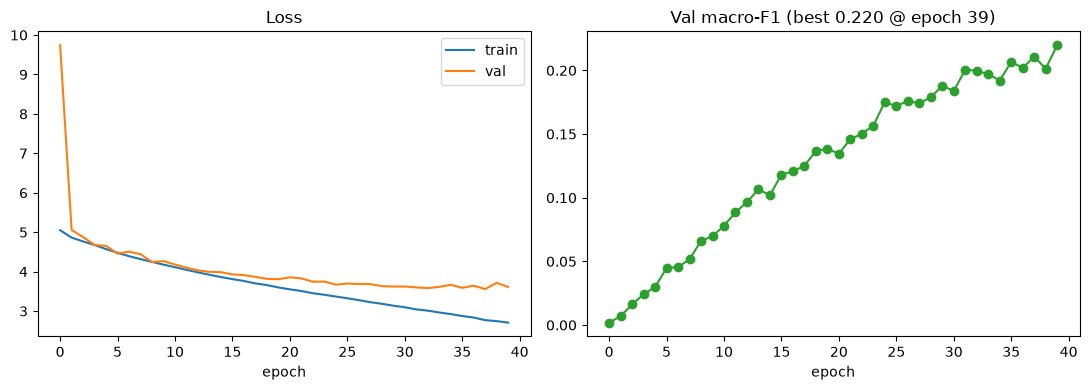

===== pmoe_scratch_e8_l8_trunk_6072k-6feddf_aug
Epoch 1/40


E0000 00:00:1795039489.053483   23935 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0294 - loss: 5.0326  val macro-F1 0.0042
329/329 ━━━━━━━━━━━━━━━━━━━━ 41s 92ms/step - accuracy: 0.0294 - loss: 5.0327 - val_accuracy: 0.0179 - val_loss: 6.4693 - val_f1: 0.0042
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0474 - loss: 4.8178  val macro-F1 0.0101
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 86ms/step - accuracy: 0.0475 - loss: 4.8179 - val_accuracy: 0.0384 - val_loss: 5.0921 - val_f1: 0.0101
Epoch 3/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0605 - loss: 4.6984  val macro-F1 0.0211
329/329 ━━━━━━━━━━━━━━━━━━━━ 29s 87ms/step - accuracy: 0.0605 - loss: 4.6984 - val_accuracy: 0.0567 - val_loss: 4.7793 - val_f1: 0.0211
Epoch 4/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0740 - loss: 4.5969  val macro-F1 0.0296
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 86ms/step - accuracy: 0.0740 - loss: 4.5973 - val_accuracy: 0.0696 - val_loss: 4.6777 - val_f1: 0.0296
Epoch 5/40
328/329 ━━━━━━━━━━━━━━━━

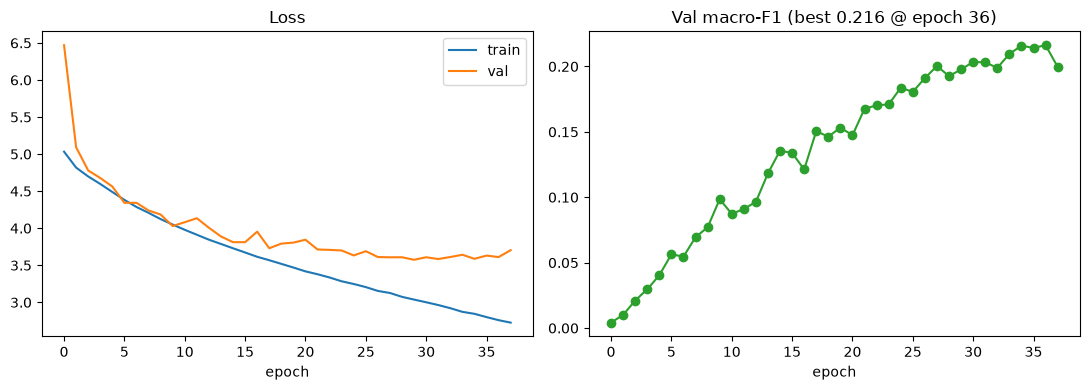

===== pmoe_scratch_e8_l16_trunk_6072k-6feddf_aug
Epoch 1/40


E0000 00:00:1795040585.138891   23935 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0287 - loss: 5.0185  val macro-F1 0.0040
329/329 ━━━━━━━━━━━━━━━━━━━━ 41s 91ms/step - accuracy: 0.0287 - loss: 5.0184 - val_accuracy: 0.0250 - val_loss: 5.2658 - val_f1: 0.0040
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0452 - loss: 4.8422  val macro-F1 0.0081
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 86ms/step - accuracy: 0.0452 - loss: 4.8424 - val_accuracy: 0.0331 - val_loss: 5.0812 - val_f1: 0.0081
Epoch 3/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0591 - loss: 4.7255  val macro-F1 0.0158
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 86ms/step - accuracy: 0.0591 - loss: 4.7254 - val_accuracy: 0.0443 - val_loss: 4.8788 - val_f1: 0.0158
Epoch 4/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0755 - loss: 4.6032  val macro-F1 0.0303
329/329 ━━━━━━━━━━━━━━━━━━━━ 28s 86ms/step - accuracy: 0.0755 - loss: 4.6032 - val_accuracy: 0.0792 - val_loss: 4.6301 - val_f1: 0.0303
Epoch 5/40
328/329 ━━━━━━━━━━━━━━━━

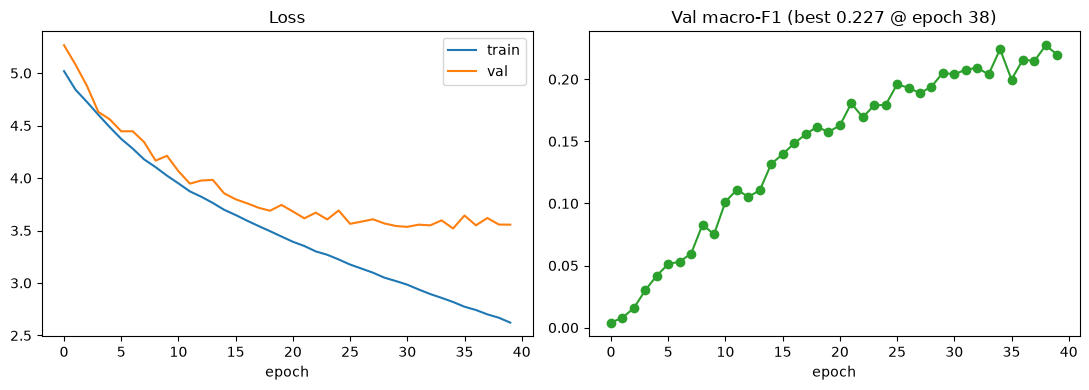

In [12]:
for key, cfg in PMOE_GRID.items():
    get_run(f'pmoe_{MODE}_{key}_{BACKBONE_ID}',
            lambda: build_pmoe(SIZE, len(classes), augmentation=AUG, backbone_fn=BB.last, lr=RUN_LR, **cfg),
            'pmoe', key)

## MGE sweep

===== mge_scratch_div0.1_trunk_6072k-6feddf_aug
Epoch 1/40


E0000 00:00:1795041738.414201   23935 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/mge_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.0295 - ensemble_loss: 5.0994 - expert_0_accuracy: 0.0257 - expert_0_loss: 5.1655 - expert_1_accuracy: 0.0238 - expert_1_loss: 5.1800 - expert_2_accuracy: 0.0225 - expert_2_loss: 5.1766 - loss: 20.7076  val macro-F1 0.0049
329/329 ━━━━━━━━━━━━━━━━━━━━ 38s 87ms/step - ensemble_accuracy: 0.0296 - ensemble_loss: 5.0986 - expert_0_accuracy: 0.0258 - expert_0_loss: 5.1648 - expert_1_accuracy: 0.0239 - expert_1_loss: 5.1791 - expert_2_accuracy: 0.0225 - expert_2_loss: 5.1761 - loss: 20.7072 - val_ensemble_accuracy: 0.0253 - val_ensemble_loss: 5.0712 - val_expert_0_accuracy: 0.0306 - val_expert_0_loss: 5.0734 - val_expert_1_accuracy: 0.0248 - val_expert_1_loss: 5.0841 - val_expert_2_accuracy: 0.0180 - val_expert_2_loss: 5.1258 - val_loss: 20.4146 - val_f1: 0.0049
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.0470 - ensemble_loss: 4.8531 - expert_0_accuracy: 0.0426 - expert_0_loss: 4.9280 - expert_1_a

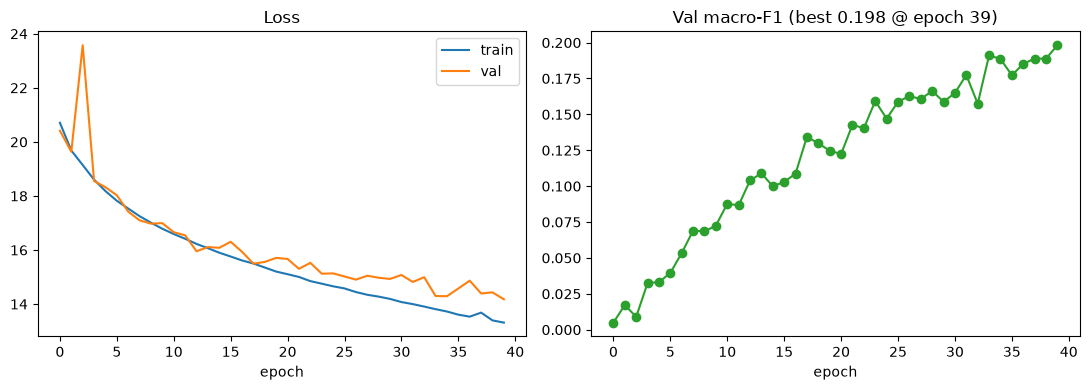

===== mge_scratch_div0_trunk_6072k-6feddf_aug
Epoch 1/40


E0000 00:00:1795042852.435095   23935 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/mge_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.0265 - ensemble_loss: 5.0949 - expert_0_accuracy: 0.0225 - expert_0_loss: 5.1746 - expert_1_accuracy: 0.0236 - expert_1_loss: 5.1790 - expert_2_accuracy: 0.0212 - expert_2_loss: 5.1499 - loss: 20.5983  val macro-F1 0.0082
329/329 ━━━━━━━━━━━━━━━━━━━━ 38s 87ms/step - ensemble_accuracy: 0.0265 - ensemble_loss: 5.0931 - expert_0_accuracy: 0.0225 - expert_0_loss: 5.1733 - expert_1_accuracy: 0.0236 - expert_1_loss: 5.1769 - expert_2_accuracy: 0.0212 - expert_2_loss: 5.1480 - loss: 20.5975 - val_ensemble_accuracy: 0.0252 - val_ensemble_loss: 5.0732 - val_expert_0_accuracy: 0.0258 - val_expert_0_loss: 5.0674 - val_expert_1_accuracy: 0.0218 - val_expert_1_loss: 5.0825 - val_expert_2_accuracy: 0.0201 - val_expert_2_loss: 5.1718 - val_loss: 20.3587 - val_f1: 0.0082
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.0469 - ensemble_loss: 4.8562 - expert_0_accuracy: 0.0417 - expert_0_loss: 4.9229 - expert_1_a

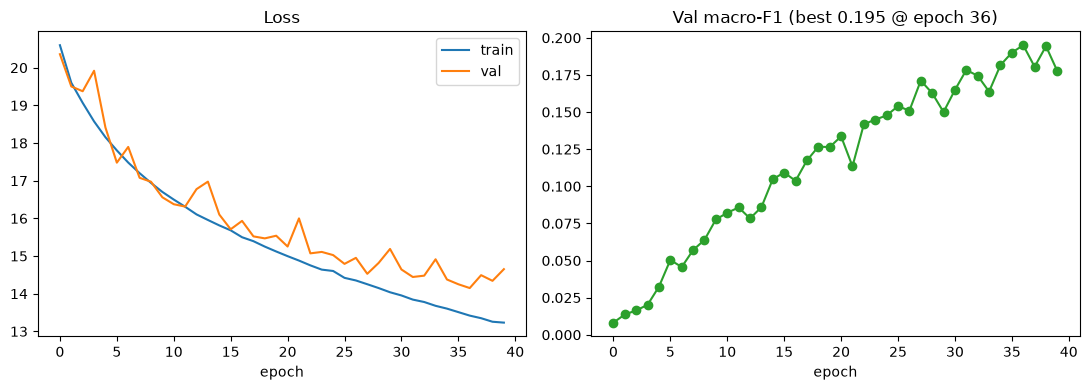

===== mge_scratch_div0.3_trunk_6072k-6feddf_aug
Epoch 1/40


E0000 00:00:1795043969.666441   23935 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/mge_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.0299 - ensemble_loss: 5.0591 - expert_0_accuracy: 0.0282 - expert_0_loss: 5.1442 - expert_1_accuracy: 0.0242 - expert_1_loss: 5.1580 - expert_2_accuracy: 0.0245 - expert_2_loss: 5.1509 - loss: 20.7570  val macro-F1 0.0042
329/329 ━━━━━━━━━━━━━━━━━━━━ 38s 87ms/step - ensemble_accuracy: 0.0299 - ensemble_loss: 5.0589 - expert_0_accuracy: 0.0282 - expert_0_loss: 5.1440 - expert_1_accuracy: 0.0242 - expert_1_loss: 5.1573 - expert_2_accuracy: 0.0245 - expert_2_loss: 5.1511 - loss: 20.7569 - val_ensemble_accuracy: 0.0204 - val_ensemble_loss: 5.1040 - val_expert_0_accuracy: 0.0272 - val_expert_0_loss: 5.0638 - val_expert_1_accuracy: 0.0199 - val_expert_1_loss: 5.1306 - val_expert_2_accuracy: 0.0173 - val_expert_2_loss: 5.2023 - val_loss: 20.7412 - val_f1: 0.0042
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.0541 - ensemble_loss: 4.7998 - expert_0_accuracy: 0.0461 - expert_0_loss: 4.8822 - expert_1_a

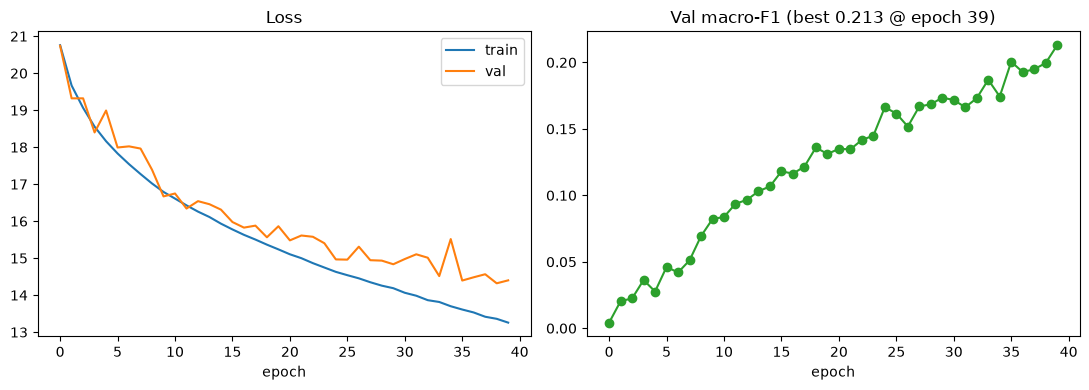

In [13]:
for key, cfg in MGE_GRID.items():
    get_run(f'mge_{MODE}_{key}_{BACKBONE_ID}',
            lambda: build_mge(SIZE, len(classes), augmentation=AUG, backbone_fn=BB.maps, lr=RUN_LR, **cfg),
            'mge', key)

## Comparison
All choices are made on the **validation** set. For MGE the figures use its `ensemble` output.
Runs of the other mode (scratch / fine-tuned) whose logs exist are added, so both appear side by side.

In [14]:
# add the runs of the OTHER mode (scratch / ft) whose logs exist, so both can be compared side by side
for model, grid in (('pmoe', PMOE_GRID), ('mge', MGE_GRID)):
    for key in grid:
        for mode in ('scratch', 'ft'):
            name = f'{model}_{mode}_{key}_{IDS[mode]}'
            path = os.path.join(HISTORY_DIR, f'{name}.csv')
            if name not in RUNS and os.path.exists(path):
                RUNS[name] = dict(model=model, mode=mode, settings=key, log=pd.read_csv(path), net=None)


def runs_of(model, mode=None):
    return {n: r for n, r in RUNS.items() if r['model'] == model and (mode is None or r['mode'] == mode)}


def label(r):
    return f"{r['model']} {r['mode']} {r['settings']}"


def val_acc(log):
    return log['val_ensemble_accuracy'] if 'val_ensemble_accuracy' in log else log['val_accuracy']


summary = pd.DataFrame([dict(run=n, model=r['model'], mode=r['mode'], settings=r['settings'],
                             epochs_run=len(r['log']), best_val_f1=r['log']['val_f1'].max(),
                             at_epoch=int(r['log']['val_f1'].values.argmax()), best_val_acc=val_acc(r['log']).max())
                        for n, r in RUNS.items()]).sort_values('best_val_f1', ascending=False)
best = {m: summary[summary['model'] == m]['run'].iloc[0] for m in ['pmoe', 'mge'] if (summary['model'] == m).any()}
print('best on val:', best)
summary.round(4)

best on val: {'pmoe': 'pmoe_scratch_e8_l16_trunk_6072k-6feddf_aug', 'mge': 'mge_scratch_div0.3_trunk_6072k-6feddf_aug'}


,run,model,mode,settings,epochs_run,best_val_f1,at_epoch,best_val_acc
2,pmoe_scratch_e8_l16_trunk_6072k-6feddf_aug,pmoe,scratch,e8_l16,40,0.2274,38,0.2871
0,pmoe_scratch_e4_l8_trunk_6072k-6feddf_aug,pmoe,scratch,e4_l8,40,0.2198,39,0.2777
1,pmoe_scratch_e8_l8_trunk_6072k-6feddf_aug,pmoe,scratch,e8_l8,38,0.2162,36,0.2727
5,mge_scratch_div0.3_trunk_6072k-6feddf_aug,mge,scratch,div0.3,40,0.2129,39,0.2926
3,mge_scratch_div0.1_trunk_6072k-6feddf_aug,mge,scratch,div0.1,40,0.1982,39,0.2843
4,mge_scratch_div0_trunk_6072k-6feddf_aug,mge,scratch,div0,40,0.1950,36,0.2804


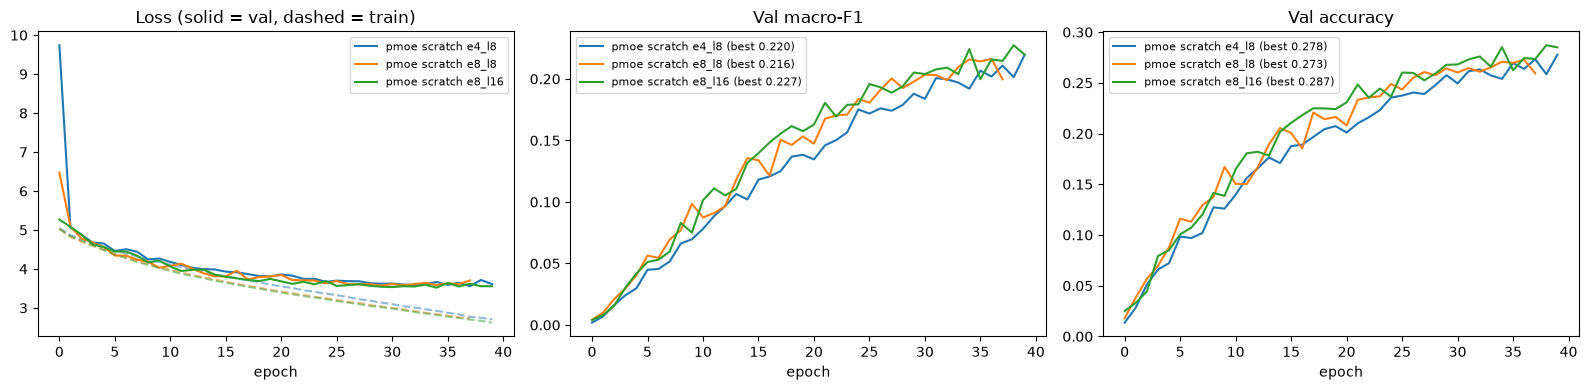

In [15]:
# pMoE: from scratch vs every fine-tuned setting
plotting.plot_comparison({label(r): r['log'] for r in runs_of('pmoe').values()})

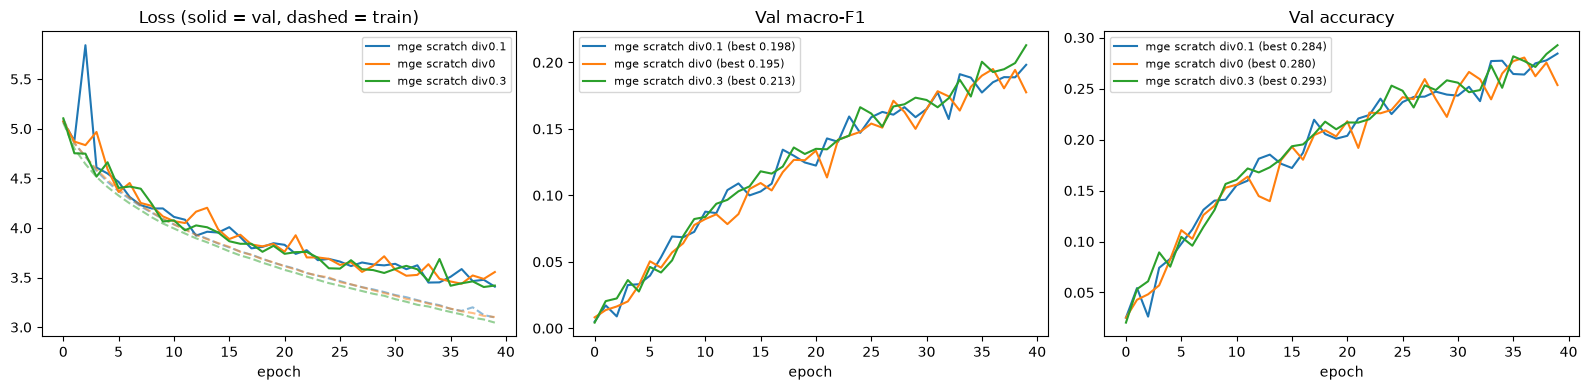

In [16]:
# MGE: from scratch vs every fine-tuned setting
plotting.plot_comparison({label(r): r['log'] for r in runs_of('mge').values()})

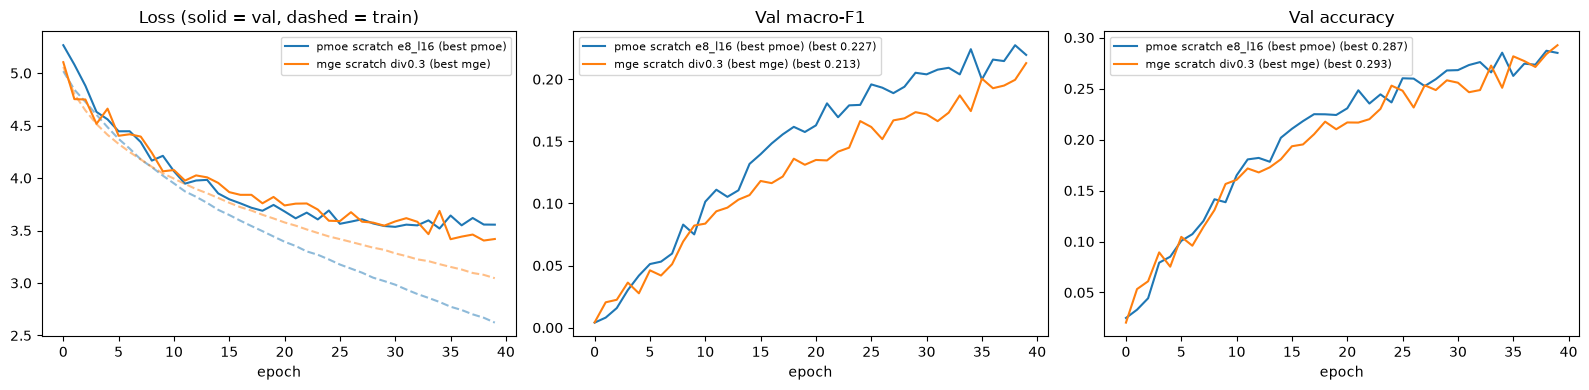

In [17]:
# head to head: the best pMoE vs the best MGE, each next to its best run of the other mode (scratch / ft)
h2h = {}
for m, n in best.items():
    h2h[f'{label(RUNS[n])} (best {m})'] = RUNS[n]['log']
    other = {s: r for s, r in runs_of(m).items() if r['mode'] != RUNS[n]['mode']}
    if other:
        s = max(other, key=lambda s: other[s]['log']['val_f1'].max())
        h2h[f"{label(other[s])} (best {other[s]['mode']})"] = other[s]['log']
plotting.plot_comparison(h2h)

## The two winners up close
pMoE: which patches each expert picks (needs the trained model, so not for a run read from its log).
MGE: how good each expert is on its own.

pmoe_scratch_e8_l16_trunk_6072k-6feddf_aug: top_idx (64, 8, 16) = (images, experts, l patches);  patch grid (8, 8)


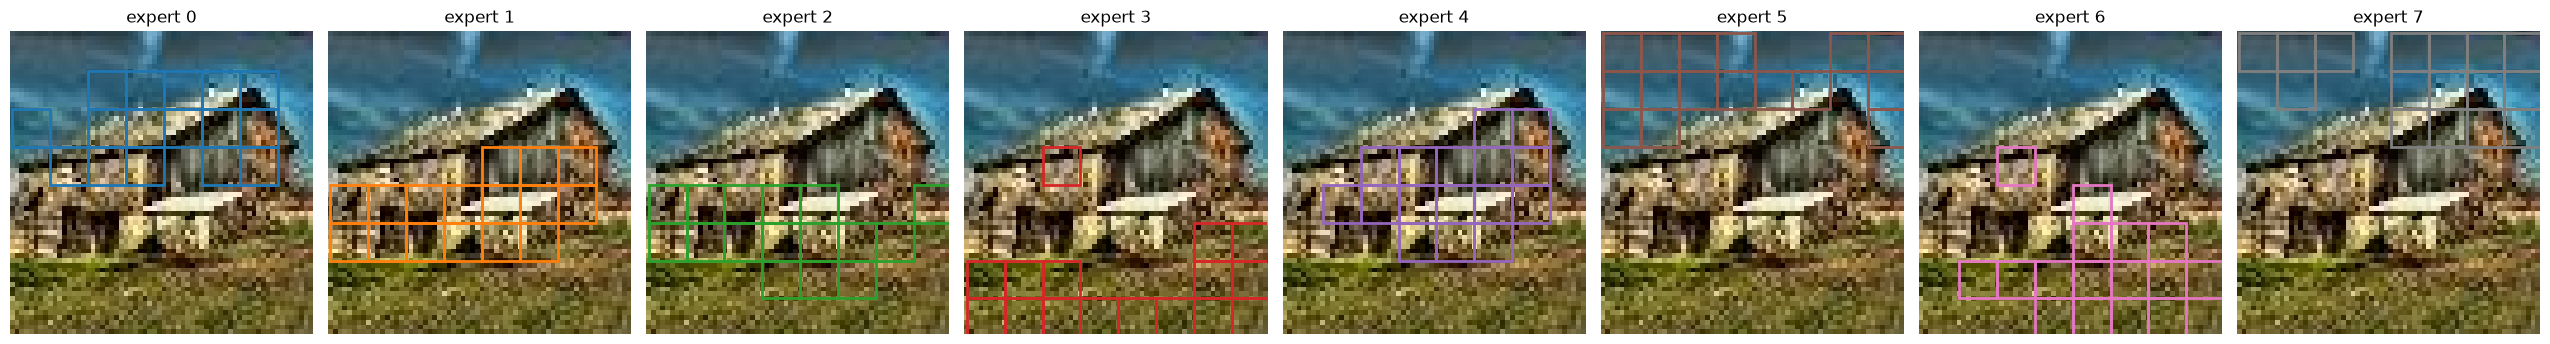

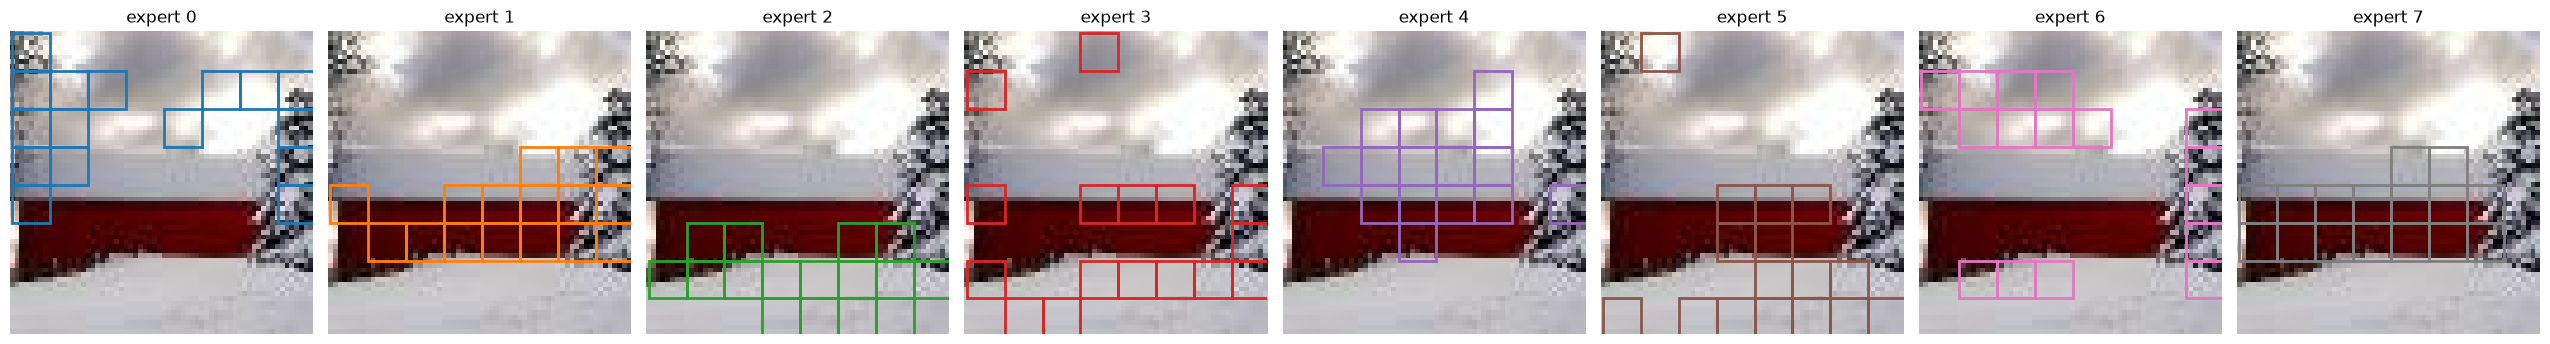

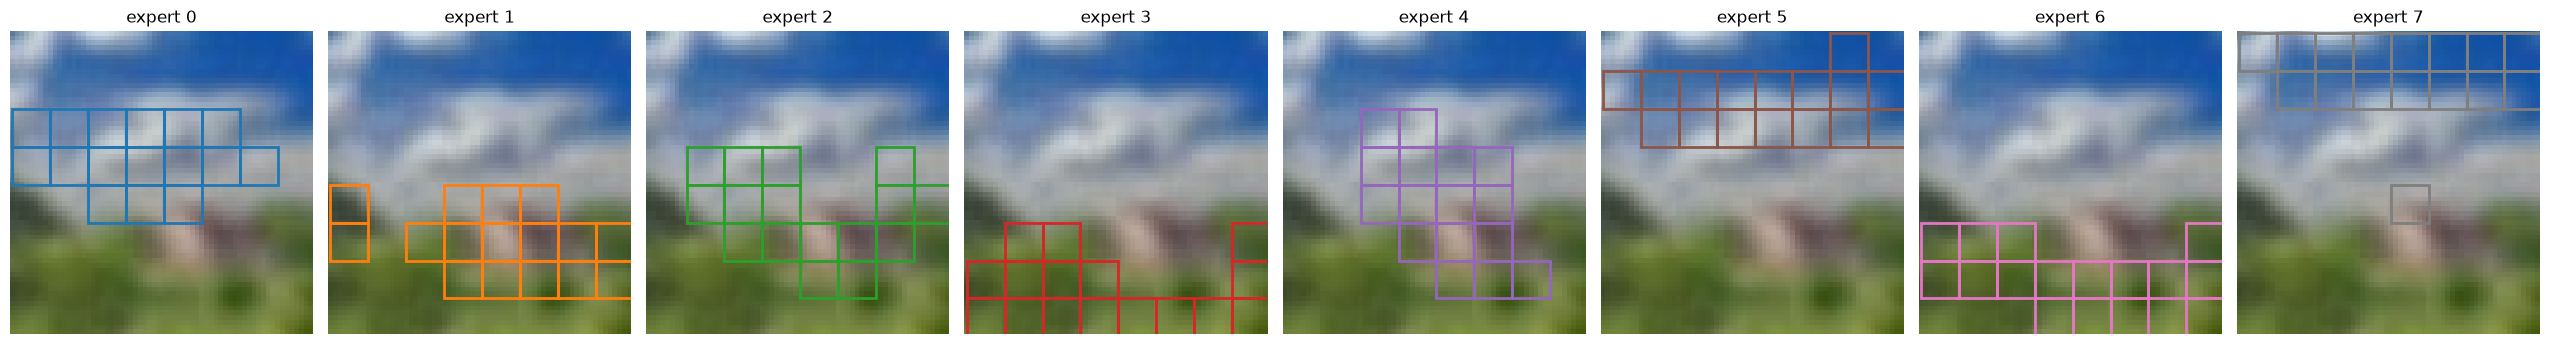

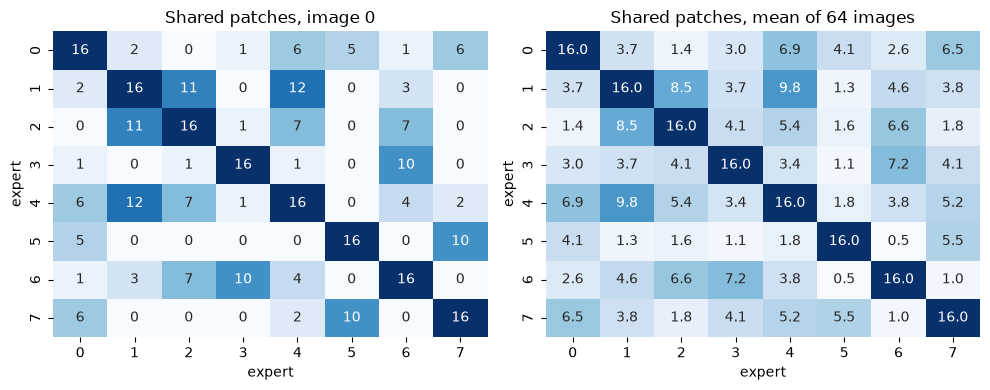

In [18]:
n = best['pmoe']
net = RUNS[n]['net']
if net is None:
    print(f'{n} was read from its log: re-run it with REUSE_LOGS = False to see its patches')
else:
    images, _ = next(iter(val))
    top_idx, gates, grid = expert_choices(net, images[:64])
    print(f'{n}: top_idx {top_idx.shape} = (images, experts, l patches);  patch grid {grid}')
    for i in range(3):
        plotting.show_expert_patches(images[i].numpy(), top_idx[i], grid)

    # do the experts pick different patches? (the diagonal is l; big off-diagonal numbers = no specialisation)
    k = top_idx.shape[1]
    def overlap(i):
        return np.array([[len(set(top_idx[i, a]) & set(top_idx[i, b])) for b in range(k)] for a in range(k)])
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    sns.heatmap(overlap(0), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
    ax[0].set(title='Shared patches, image 0', xlabel='expert', ylabel='expert')
    sns.heatmap(np.mean([overlap(i) for i in range(len(top_idx))], axis=0), annot=True, fmt='.1f', cmap='Blues',
                cbar=False, ax=ax[1])
    ax[1].set(title=f'Shared patches, mean of {len(top_idx)} images', xlabel='expert', ylabel='expert')
    plt.tight_layout(); plt.show()

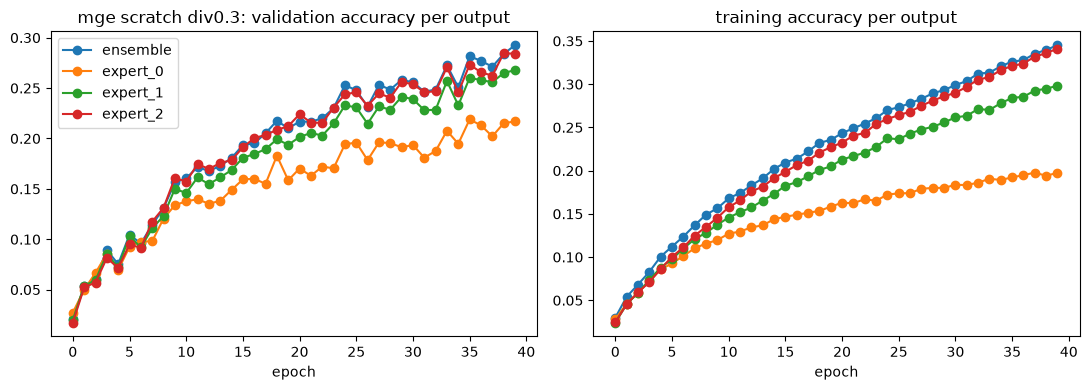

best val accuracy: {'ensemble': 0.2926, 'expert_0': 0.2189, 'expert_1': 0.2679, 'expert_2': 0.2844}


In [19]:
n = best['mge']
h = RUNS[n]['log']
outputs = ['ensemble', 'expert_0', 'expert_1', 'expert_2']
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for o in outputs:
    ax[0].plot(h[f'val_{o}_accuracy'].values, marker='o', label=o)
    ax[1].plot(h[f'{o}_accuracy'].values, marker='o', label=o)
ax[0].set(title=f'{label(RUNS[n])}: validation accuracy per output', xlabel='epoch')
ax[1].set(title='training accuracy per output', xlabel='epoch')
ax[0].legend(); plt.tight_layout(); plt.show()
print('best val accuracy:', {o: round(float(h[f'val_{o}_accuracy'].max()), 4) for o in outputs})

## Test set (once, for the two winners)
The settings were chosen on validation; the test set only reports how good the chosen models are.

In [20]:
y_test = np.concatenate([y.numpy() for _, y in test])
for m, n in best.items():
    net = RUNS[n]['net']
    if net is None:
        print(f'{m}: {n} was read from its log, no model to test (re-run it with REUSE_LOGS = False)')
        continue
    pred = net.predict(test, verbose=0)
    if isinstance(pred, (list, tuple)):          # MGE: the first output is the ensemble
        pred = pred[0]
    p = pred.argmax(1)
    print(f'{m:5s} {n}: test macro-F1 {f1_score(y_test, p, average="macro"):.4f}   accuracy {(p == y_test).mean():.4f}')

pmoe  pmoe_scratch_e8_l16_trunk_6072k-6feddf_aug: test macro-F1 0.2112   accuracy 0.2738
mge   mge_scratch_div0.3_trunk_6072k-6feddf_aug: test macro-F1 0.2039   accuracy 0.2861


In [ ]:
# save the winners' weights (best epoch, because EarlyStopping restores the best weights)
os.makedirs('models', exist_ok=True)
for m, n in best.items():
    net = RUNS[n]['net']
    if net is None:
        continue
    path = f'models/{n}.weights.h5'
    net.save_weights(path)
    print(f'saved {os.path.getsize(path) / 1e6:.1f} MB -> {path}')
    if USE_GITHUB:                               # Colab: the VM disk disappears, so commit it as well
        push_files({path: path}, f'model weights: {n}')